# GSE96058 Dataset Preparation and Exploratory Data Analysis

## Objective
Inspect the GSE96058 breast-cancer gene-expression dataset, verify its integrity, extract the GEO-recorded PAM50 subtype labels, and create reproducible analysis-ready exports for downstream modeling.

## Data source and exact expression scale
- **GEO series:** [GSE96058](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE96058), SCAN-B breast cancer cohort.
- **Expression matrix:** `GSE96058_gene_expression_3273_samples_and_136_replicates_transformed.csv.gz` (official GEO supplementary file).
- **Metadata:** `GSE96058_family.soft.gz` (GEO family SOFT file).
- **Target:** GEO sample characteristic `PAM50 subtype`.

The supplementary expression matrix is **not raw read counts and not FPKM in its original scale**. The dataset processing description states that transcript-level FPKM values were collapsed to 30,865 gene symbols by summing matching-transcript FPKM values, then **0.1 FPKM was added and values were log2-transformed**: `log2(FPKM + 0.1)`. The GEO record describes the supplementary file as transformed expression values. This notebook uses those provided values as-is; it does not re-normalize or re-transform them. Sources: [GSE96058 processing notes](https://github.com/12379Monty/GSE96058) and [GEO sample record](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM2528375).

## How to run
Run the notebook from top to bottom in Google Colab or another Python environment with internet access. The first data setup cell downloads the official expression file to `/content/`; the metadata cell downloads the SOFT file. The cleaned dataset and label exports are regenerated under `/content/data/processed/`. The downloaded data and generated outputs should not be committed to GitHub.

No raw sequencing processing or FastQC analysis is performed because this project uses GEO's processed expression matrix.

## 1. Obtain the expression matrix

The next code cell downloads the exact official GEO supplementary expression file if it is not already present. Expected variable after this cell: `filename` (path to the gzip-compressed CSV). The file's first column contains gene symbols and the remaining columns contain expression sample IDs, including technical replicate columns whose IDs end in `repl`.

Direct source: [GSE96058 supplementary files](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE96058).

In [ ]:

import os

# List files uploaded to Colab
os.listdir("/content")


['.config', 'sample_data']

In [ ]:
import os
import urllib.request

EXPRESSION_URL = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE96nnn/GSE96058/suppl/"
    "GSE96058_gene_expression_3273_samples_and_136_replicates_transformed.csv.gz"
)
DATA_DIR = "/content"
filename = os.path.join(
    DATA_DIR,
    "GSE96058_gene_expression_3273_samples_and_136_replicates_transformed.csv.gz"
)
os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(filename):
    print("Downloading official GSE96058 transformed expression matrix...")
    urllib.request.urlretrieve(EXPRESSION_URL, filename)

print("Expression file:", filename)
print("File size (MB):", round(os.path.getsize(filename) / 1024**2, 2))

Expression file: /content/GSE96058_gene_expression_3273_samples_and_136_replicates_transformed.csv.gz
File size (MB): 564.27


## 2. Inspect the file structure and find label metadata

The following cells inspect the first lines and a small preview of the compressed CSV, including its dimensions, leading and trailing column names, data types, and missing values. They also search the preview headers for possible sample or label fields. These checks help establish that the first column holds gene identifiers and the remaining columns represent expression samples; the PAM50 labels are obtained separately from GEO metadata.


In [ ]:

import gzip

with gzip.open(filename, "rt") as f:
    for i in range(5):
        print(f"\nLine {i + 1}:")
        print(f.readline()[:500])



Line 1:
"","F1","F2","F3","F4","F5","F6","F7","F8","F9","F10","F11","F12","F13","F14","F15","F16","F17","F18","F19","F20","F21","F22","F23","F24","F25","F26","F27","F28","F29","F30","F31","F32","F33","F34","F35","F36","F37","F38","F39","F40","F41","F42","F43","F44","F45","F46","F47","F48","F49","F50","F51","F52","F53","F54","F55","F56","F57","F58","F59","F60","F61","F62","F63","F64","F65","F66","F67","F68","F69","F70","F71","F72","F73","F74","F75","F76","F77","F78","F79","F80","F81","F82","F83","F84","F

Line 2:
"5_8S_rRNA",-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-3.32192809488736,-

In [ ]:

import pandas as pd

df_preview = pd.read_csv(
    filename,
    compression="gzip",
    nrows=5
)

print("Preview dimensions:", df_preview.shape)

print("\nFirst 15 column names:")
print(df_preview.columns[:15].tolist())

print("\nLast 10 column names:")
print(df_preview.columns[-10:].tolist())

print("\nFirst 5 rows and first 6 columns:")
display(df_preview.iloc[:, :6])


Preview dimensions: (5, 3410)

First 15 column names:
['Unnamed: 0', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'F8', 'F9', 'F10', 'F11', 'F12', 'F13', 'F14']

Last 10 column names:
['F2974repl', 'F3006repl', 'F3028repl', 'F3057repl', 'F3058repl', 'F3085repl', 'F3127repl', 'F3135repl', 'F3250repl', 'F3265repl']

First 5 rows and first 6 columns:


,Unnamed: 0,F1,F2,F3,F4,F5
0,5_8S_rRNA,-3.321928,-3.321928,-3.321928,-3.321928,-3.321928
1,5S_rRNA,4.911099,-3.321928,-3.321928,3.656393,4.190104
2,6M1-18,-3.321928,-3.321928,-3.321928,-3.321928,-3.321928
3,7M1-2,-3.321928,-3.321928,-3.321928,-3.321928,-3.321928
4,7SK,-0.539253,-0.576620,-1.651323,0.126633,0.783715


In [ ]:

keywords = [
    "subtype", "pam50", "label",
    "class", "diagnosis", "patient",
    "sample", "replicate"
]

matches = [
    col for col in df_preview.columns
    if any(word in str(col).lower() for word in keywords)
]

print("Potential label or metadata columns:")
print(matches)

print("\nFirst few column data types:")
print(df_preview.iloc[:, :6].dtypes)

print("\nMissing values in the preview:")
print(df_preview.iloc[:, :6].isna().sum())


Potential label or metadata columns:
[]

First few column data types:
Unnamed: 0     object
F1            float64
F2            float64
F3            float64
F4            float64
F5            float64
dtype: object

Missing values in the preview:
Unnamed: 0    0
F1            0
F2            0
F3            0
F4            0
F5            0
dtype: int64


## 3. Extract and match PAM50 labels from GEO SOFT metadata

The SOFT parser records each `^SAMPLE` accession, its `!Sample_title`, and the `!Sample_characteristics_ch1` entry beginning with `PAM50 subtype:`. **The expression matrix column names are matched to SOFT `!Sample_title` values**, not to GSM accessions. The resulting `label_map` is indexed by title/sample ID and is reindexed to the expression sample order when labels are attached. The code reports unmatched IDs before preparing the dataset; do not silently infer labels for unmatched samples.

In [ ]:

import urllib.request
import gzip
import os

url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE96nnn/GSE96058/soft/"
    "GSE96058_family.soft.gz"
)

metadata_path = "/content/GSE96058_family.soft.gz"

if not os.path.exists(metadata_path):
    print("Downloading GEO sample metadata...")
    urllib.request.urlretrieve(url, metadata_path)

print("Metadata file ready:", metadata_path)

# Search the metadata for sample IDs, titles and PAM50 labels
with gzip.open(metadata_path, "rt", errors="replace") as f:
    lines = f.readlines()

print("Total metadata lines:", len(lines))

print("\nLines mentioning PAM50:")
pam_lines = [
    (i, line.strip())
    for i, line in enumerate(lines)
    if "pam50" in line.lower()
]

for i, line in pam_lines[:30]:
    print(f"Line {i}: {line[:300]}")

print("\nSample titles near the beginning:")
title_lines = [
    line.strip() for line in lines
    if line.startswith("!Sample_title")
]

for line in title_lines[:10]:
    print(line)


Metadata file ready: /content/GSE96058_family.soft.gz
Total metadata lines: 252157

Lines mentioning PAM50:
Line 26: !Series_overall_design = Illumina paired-end RNA-sequencing and expression estimation were performed for two cohorts: a training cohort with 405 samples (GSE81538), and a validation cohort with 3273 samples (of which 136 cases have technical replicates) (GSE96058).  A comprehensive histopathological
Line 3533: !Sample_characteristics_ch1 = pam50 subtype: Basal
Line 3551: !Sample_data_processing = PAM50 subtyping was performed using an implementation of the Parker method (Parker et al., J.Clin Oncol 2009). In short, to avoid context dependency when assigning PAM50 subtype by nearest-centroid, a fixed reference was selected to match the original cohort used by Parker 
Line 3606: !Sample_characteristics_ch1 = pam50 subtype: LumA
Line 3624: !Sample_data_processing = PAM50 subtyping was performed using an implementation of the Parker method (Parker et al., J.Clin Oncol 2009).

In [ ]:

import re
import gzip
import pandas as pd
from collections import Counter

metadata_path = "/content/GSE96058_family.soft.gz"

records = []
current = {}

def save_sample(sample):
    if sample.get("title"):
        records.append(sample.copy())

with gzip.open(metadata_path, "rt", errors="replace") as f:
    for line in f:
        line = line.rstrip("\n")

        if line.startswith("^SAMPLE = "):
            save_sample(current)
            current = {"accession": line.split("=", 1)[1].strip()}

        elif line.startswith("!Sample_title = "):
            current["title"] = line.split("=", 1)[1].strip()

        elif line.startswith("!Sample_characteristics_ch1 = "):
            value = line.split("=", 1)[1].strip()

            if value.lower().startswith("pam50 subtype:"):
                current["pam50"] = value.split(":", 1)[1].strip()

save_sample(current)

labels = pd.DataFrame(records).drop_duplicates(
    subset=["title"], keep="first"
)

print("Samples with metadata:", len(labels))
print("\nPAM50 label counts:")
print(labels["pam50"].value_counts(dropna=False))

print("\nExample extracted labels:")
display(labels[["title", "pam50"]].head(10))

# Compare sample IDs with the expression matrix columns
expression_ids = set(df_preview.columns[1:])
metadata_ids = set(labels["title"])

print("\nExpression sample columns:", len(expression_ids))
print("Metadata sample IDs:", len(metadata_ids))
print("IDs present in both:", len(expression_ids & metadata_ids))
print("Expression IDs without metadata:",
      len(expression_ids - metadata_ids))
print("Metadata IDs without expression:",
      len(metadata_ids - expression_ids))

print("\nExample unmatched expression IDs:")
print(sorted(expression_ids - metadata_ids)[:20])


Samples with metadata: 3409

PAM50 label counts:
pam50
LumA      1709
LumB       767
Basal      360
Her2       348
Normal     225
Name: count, dtype: int64

Example extracted labels:


,title,pam50
0,F1,Basal
1,F2,LumA
2,F3,LumB
3,F4,LumA
4,F5,Normal
5,F6,Basal
6,F7,Normal
7,F8,Normal
8,F9,Her2
9,F10,LumA



Expression sample columns: 3409
Metadata sample IDs: 3409
IDs present in both: 3409
Expression IDs without metadata: 0
Metadata IDs without expression: 0

Example unmatched expression IDs:
[]


## 4. Identify technical replicates

Expression columns ending in `repl` are treated as technical replicate measurements, as indicated by the dataset's sample naming convention. The notebook lists these columns and checks subtype totals and label coverage. The final preparation excludes these replicate columns so that each retained row represents one primary sample rather than counting a repeated technical measurement as an independent sample.


In [ ]:

import pandas as pd

# Display sample IDs that appear to be technical replicates
replicate_ids = [
    col for col in df_preview.columns[1:]
    if str(col).lower().endswith("repl")
]

print("Number of replicate columns:", len(replicate_ids))
print("\nReplicate sample IDs:")
print(replicate_ids)

# Display example sample IDs
print("\nFirst 20 sample IDs:")
print(df_preview.columns[1:21].tolist())

# Confirm subtype label totals
print("\nSubtype totals:")
print(labels["pam50"].value_counts())

# Check that every expression column has a label
print("\nAll expression columns labeled:",
      set(df_preview.columns[1:]) == set(labels["title"]))


Number of replicate columns: 136

Replicate sample IDs:
['F8repl', 'F30repl', 'F49repl', 'F54repl', 'F69repl', 'F73repl', 'F112repl', 'F116repl', 'F184repl', 'F185repl', 'F187repl', 'F218repl', 'F229repl', 'F274repl', 'F282repl', 'F327repl', 'F405repl', 'F437repl', 'F445repl', 'F461repl', 'F498repl', 'F542repl', 'F545repl', 'F573repl', 'F574repl', 'F673repl', 'F679repl', 'F685repl', 'F713repl', 'F717repl', 'F724repl', 'F748repl', 'F766repl', 'F777repl', 'F781repl', 'F783repl', 'F784repl', 'F785repl', 'F799repl', 'F803repl', 'F804repl', 'F807repl', 'F813repl', 'F833repl', 'F847repl', 'F895repl', 'F912repl', 'F933repl', 'F934repl', 'F1101repl', 'F1108repl', 'F1143repl', 'F1156repl', 'F1167repl', 'F1197repl', 'F1214repl', 'F1283repl', 'F1392repl', 'F1438repl', 'F1439repl', 'F1497repl', 'F1515repl', 'F1519repl', 'F1580repl', 'F1581repl', 'F1582repl', 'F1584repl', 'F1587repl', 'F1591repl', 'F1605repl', 'F1617repl', 'F1628repl', 'F1635repl', 'F1640repl', 'F1648repl', 'F1658repl', 'F1689repl'

## 5. Inspect the full expression matrix

The full compressed matrix is loaded and the first column is renamed `gene` for clarity. The notebook checks matrix dimensions, unique and duplicate gene identifiers, missing and infinite expression values, the expression-value range and summary statistics, and a small data preview. A separate chunked scan repeats key integrity checks across the full file without relying only on the preview. These are descriptive checks; no values are imputed, scaled, or otherwise transformed here.


In [ ]:

import pandas as pd
import numpy as np
import os

filename = "/content/GSE96058_gene_expression_3273_samples_and_136_replicates_transformed.csv.gz"

# Load the complete expression matrix
df = pd.read_csv(filename, compression="gzip")

# Rename the first column to make its purpose clear
df = df.rename(columns={df.columns[0]: "gene"})

print("Dataset shape:", df.shape)
print("Number of gene rows:", df["gene"].nunique())
print("Number of sample columns:", df.shape[1] - 1)

print("\nDuplicate gene names:", df["gene"].duplicated().sum())

values = df.drop(columns="gene")

print("\nMissing expression values:", values.isna().sum().sum())
print("Infinite values:", np.isinf(values.to_numpy()).sum())

print("\nExpression value summary:")
print(values.describe().loc[["min", "mean", "50%", "max"]])

print("\nFirst 5 genes and first 5 samples:")
display(df.iloc[:5, :6])


Dataset shape: (30865, 3410)
Number of gene rows: 30865
Number of sample columns: 3409

Duplicate gene names: 0

Missing expression values: 0
Infinite values: 0

Expression value summary:
             F1         F2         F3         F4         F5         F6  \
min   -3.321928  -3.321928  -3.321928  -3.321928  -3.321928  -3.321928   
mean  -0.208790  -0.088334  -0.161770   0.087036   0.113888   0.030815   
50%   -1.396719  -1.057725  -1.355811  -0.644959  -0.482110  -0.809219   
max   19.483096  16.226999  19.515425  20.064014  18.661987  18.603627   

             F7         F8         F9        F10  ...  F2974repl  F3006repl  \
min   -3.321928  -3.321928  -3.321928  -3.321928  ...  -3.321928  -3.321928   
mean   0.044865   0.028058   0.012661  -0.108653  ...  -0.145267  -0.159998   
50%   -0.624726  -0.651353  -0.793889  -0.986428  ...  -1.251808  -1.399977   
max   17.098362  16.383142  17.084633  20.753083  ...  19.687067  16.608801   

      F3028repl  F3057repl  F3058repl  F3085r

,gene,F1,F2,F3,F4,F5
0,5_8S_rRNA,-3.321928,-3.321928,-3.321928,-3.321928,-3.321928
1,5S_rRNA,4.911099,-3.321928,-3.321928,3.656393,4.190104
2,6M1-18,-3.321928,-3.321928,-3.321928,-3.321928,-3.321928
3,7M1-2,-3.321928,-3.321928,-3.321928,-3.321928,-3.321928
4,7SK,-0.539253,-0.576620,-1.651323,0.126633,0.783715


In [ ]:

import pandas as pd
import numpy as np

filename = "/content/GSE96058_gene_expression_3273_samples_and_136_replicates_transformed.csv.gz"

total_rows = 0
missing_values = 0
infinite_values = 0
gene_ids = set()
duplicate_gene_count = 0
min_value = float("inf")
max_value = float("-inf")

for chunk in pd.read_csv(
    filename,
    compression="gzip",
    chunksize=2000
):
    # The first column contains gene names
    genes = chunk.iloc[:, 0].astype(str)

    # Check against ALL previously processed chunks, not just this chunk.
    # This catches repeated identifiers even if they occur in separate chunks.
    for gene in genes:
        if gene in gene_ids:
            duplicate_gene_count += 1
        else:
            gene_ids.add(gene)

    # Inspect expression values
    values = chunk.iloc[:, 1:].to_numpy(dtype=float)

    missing_values += np.isnan(values).sum()
    infinite_values += np.isinf(values).sum()

    finite_values = values[np.isfinite(values)]
    if finite_values.size:
        min_value = min(min_value, finite_values.min())
        max_value = max(max_value, finite_values.max())

    total_rows += len(chunk)

print("Gene rows:", total_rows)
print("Unique gene names:", len(gene_ids))
print("Duplicate gene names:", duplicate_gene_count)
print("Missing expression values:", missing_values)
print("Infinite expression values:", infinite_values)
print("Minimum expression value:", min_value)
print("Maximum expression value:", max_value)


Gene rows: 30865
Unique gene names: 30865
Duplicate gene names: 0
Missing expression values: 0
Infinite expression values: 0
Minimum expression value: -3.32192809488736
Maximum expression value: 25.0000932158848


## 6. Verify primary-sample label coverage

Before constructing the clean table, the code splits the expression columns into primary samples and names ending in `repl`, then checks that every primary sample has a metadata record and a non-missing PAM50 subtype. The reported counts are 3,409 total expression columns, 136 replicate columns, and 3,273 primary samples; all 3,273 primary samples have labels.


In [ ]:

# Identify primary samples and technical replicates
all_samples = df_preview.columns[1:].tolist()

replicate_samples = [
    sample for sample in all_samples
    if sample.endswith("repl")
]

primary_samples = [
    sample for sample in all_samples
    if not sample.endswith("repl")
]

# Match the GEO metadata labels to expression columns
label_map = labels.drop_duplicates(
    subset="title"
).set_index("title")["pam50"]

print("Total expression samples:", len(all_samples))
print("Technical replicates:", len(replicate_samples))
print("Primary samples:", len(primary_samples))

print("\nPrimary samples without labels:",
      sum(sample not in label_map.index for sample in primary_samples))

print("\nPrimary samples with missing PAM50 labels:",
      sum(pd.isna(label_map.get(sample)) for sample in primary_samples))

print("\nPrimary PAM50 counts:")
print(label_map.reindex(primary_samples).value_counts(dropna=False))

# Fail early if IDs or labels do not align as expected.
missing_primary_ids = sorted(set(primary_samples) - set(label_map.index))
missing_primary_labels = [s for s in primary_samples if pd.isna(label_map.get(s))]
print("\nExample primary IDs without a metadata title:", missing_primary_ids[:10])
assert not missing_primary_ids, "Some primary expression sample IDs have no matching SOFT title."
assert not missing_primary_labels, "Some primary samples have missing PAM50 labels."


Total expression samples: 3409
Technical replicates: 136
Primary samples: 3273

Primary samples without labels: 0

Primary samples with missing PAM50 labels: 0

Primary PAM50 counts:
pam50
LumA      1657
LumB       729
Basal      339
Her2       327
Normal     221
Name: count, dtype: int64

Example primary IDs without a metadata title: []


## 7. Build the sample-by-gene dataset

The final preparation keeps the gene identifier column and primary-sample columns only, uses gene identifiers as the index, then transposes the matrix so samples are rows and genes are columns. PAM50 labels are reindexed to the transposed sample index before being attached, ensuring labels follow the exact expression-row order.

The resulting `X` has **3,273 rows and 30,866 columns**: one sample identifier in the index, 30,865 gene-expression features, and one `PAM50` target column. It has 3,273 unique samples, no missing PAM50 labels, and subtype counts of LumA 1,657; LumB 729; Basal 339; Her2 327; and Normal 221. The displayed preview shows the first five samples and first few gene columns.


In [ ]:
# Load the expression matrix; first column is gene symbol, remaining columns are sample IDs.
df = pd.read_csv(filename, compression="gzip")
df = df.rename(columns={df.columns[0]: "gene"})

# Technical replicate columns have the documented `repl` suffix and are excluded.
primary_samples = [col for col in df.columns[1:] if not str(col).endswith("repl")]

# Expression matrix is genes x samples; transpose to samples x genes.
X = df[["gene"] + primary_samples].set_index("gene").T
X.index.name = "sample_id"

# Reindex by expression sample IDs so labels follow the exact row order.
X["PAM50"] = label_map.reindex(X.index)

print("Clean dataset shape (samples x [genes + PAM50]):", X.shape)
print("Unique samples:", X.index.nunique())
print("Missing PAM50 labels:", X["PAM50"].isna().sum())
print("Expression sample IDs matched in same order:", X.index.equals(pd.Index(primary_samples)))
print("\nSubtype counts:")
print(X["PAM50"].value_counts(dropna=False))

assert X.index.is_unique, "Duplicate sample IDs remain in the clean dataset."
assert X["PAM50"].notna().all(), "Missing PAM50 labels remain after matching."
assert X.shape[0] == len(primary_samples), "Unexpected sample count after excluding replicates."

display(X.iloc[:5, :6])

Clean dataset shape (samples x [genes + PAM50]): (3273, 30866)
Unique samples: 3273
Missing PAM50 labels: 0
Expression sample IDs matched in same order: True

Subtype counts:
PAM50
LumA      1657
LumB       729
Basal      339
Her2       327
Normal     221
Name: count, dtype: int64


gene,5_8S_rRNA,5S_rRNA,6M1-18,7M1-2,7SK,A1BG
sample_id,,,,,,
F1,-3.321928,4.911099,-3.321928,-3.321928,-0.539253,0.598115
F2,-3.321928,-3.321928,-3.321928,-3.321928,-0.576620,2.363673
F3,-3.321928,-3.321928,-3.321928,-3.321928,-1.651323,2.647738
F4,-3.321928,3.656393,-3.321928,-3.321928,0.126633,1.378576
F5,-3.321928,4.190104,-3.321928,-3.321928,0.783715,2.759643


## Scope and limitations

This notebook documents data inspection, sample selection, label extraction/alignment, and table orientation for a clean analysis-ready dataset. It does not train or evaluate a classifier, select genes, perform differential-expression analysis, impute data, normalize or standardize expression values, or establish clinical conclusions. The PAM50 labels are used as provided in GEO metadata, and the `repl` suffix rule is the notebook's criterion for excluding technical replicates. The `Normal` subtype is retained as a PAM50 class as encoded in the metadata; it should not be interpreted here as an independent clinical control cohort.

The underlying expression values are processed values supplied with GSE96058; this notebook does not start from raw sequencing reads or perform raw-read quality control. For reproducibility, the GEO series, expression file, and family SOFT metadata should be cited alongside any downstream analysis.


### Interpretation of the preparation result
The table is sample-by-gene: each row is one primary sample, each gene-symbol column is a processed expression feature, and `PAM50` is the metadata-derived target. The assertions ensure sample IDs remain unique and every retained sample has a matched label; these checks establish data alignment, not predictive performance.

## 8. Export the cleaned dataset and label table

The next cell regenerates two model-training inputs under `/content/data/processed/`:
- `GSE96058_clean_PAM50.csv`: one row per primary sample, gene-expression columns plus `PAM50`; sample ID saved as `sample_id`.
- `GSE96058_PAM50_labels.csv`: sample ID and PAM50 label only, useful for auditing or loading targets separately.

The export directory is created automatically. These files are generated artifacts and should remain out of GitHub (the repository `.gitignore` excludes processed data).

In [ ]:
import os

OUTPUT_DIR = "/content/data/processed"
os.makedirs(OUTPUT_DIR, exist_ok=True)

cleaned_path = os.path.join(OUTPUT_DIR, "GSE96058_clean_PAM50.csv")
labels_path = os.path.join(OUTPUT_DIR, "GSE96058_PAM50_labels.csv")

X.to_csv(cleaned_path, index_label="sample_id")
X[["PAM50"]].to_csv(labels_path, index_label="sample_id")

# Confirm both outputs exist and have the expected row counts.
assert os.path.isfile(cleaned_path) and os.path.getsize(cleaned_path) > 0
assert os.path.isfile(labels_path) and os.path.getsize(labels_path) > 0
exported = pd.read_csv(cleaned_path, nrows=5)
exported_labels = pd.read_csv(labels_path)
assert len(exported_labels) == len(X)
assert "sample_id" in exported.columns and "PAM50" in exported.columns

print("Clean matrix saved:", cleaned_path, f"({os.path.getsize(cleaned_path) / 1024**2:.1f} MB)")
print("Label table saved:", labels_path, f"({os.path.getsize(labels_path) / 1024**2:.2f} MB)")
print("Exported label rows:", len(exported_labels))
print("Exported label counts:")
print(exported_labels["PAM50"].value_counts(dropna=False))

Clean matrix saved: /content/data/processed/GSE96058_clean_PAM50.csv (1695.2 MB)
Label table saved: /content/data/processed/GSE96058_PAM50_labels.csv (0.03 MB)
Exported label rows: 3273
Exported label counts:
PAM50
LumA      1657
LumB       729
Basal      339
Her2       327
Normal     221
Name: count, dtype: int64


## Initial Exploratory Data Analysis (EDA)

This section evaluates the structure and quality of the prepared GSE96058
breast cancer gene-expression dataset before model development.

The analysis covers:
- Dataset dimensions and PAM50 subtype distribution
- Missing values, infinite values, and duplicate identifiers
- Gene-expression value distributions
- Potential data-quality issues that must be addressed before training

No machine-learning models are trained in this section.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Separate expression features and target labels
target_col = "PAM50"

assert target_col in X.columns, (
    f"Target column '{target_col}' not found. "
    f"Available columns include: {list(X.columns[:10])}"
)

gene_data = X.drop(columns=[target_col])
subtype_labels = X[target_col]

print("DATASET SUMMARY")
print("-" * 40)
print(f"Number of samples: {X.shape[0]:,}")
print(f"Number of gene features: {gene_data.shape[1]:,}")
print(f"Number of PAM50 classes: {subtype_labels.nunique()}")
print(f"Missing subtype labels: {subtype_labels.isna().sum()}")
print(f"Duplicate sample IDs: {X.index.duplicated().sum()}")
print(f"Duplicate gene identifiers: {gene_data.columns.duplicated().sum()}")
print(f"Missing expression values: {gene_data.isna().sum().sum():,}")

numeric_data = gene_data.select_dtypes(include=np.number)

print(
    "Infinite expression values:",
    np.isinf(numeric_data.to_numpy()).sum()
)

print("\nPAM50 classes:")
print(sorted(subtype_labels.dropna().unique()))

DATASET SUMMARY
----------------------------------------
Number of samples: 3,273
Number of gene features: 30,865
Number of PAM50 classes: 5
Missing subtype labels: 0
Duplicate sample IDs: 0
Duplicate gene identifiers: 0
Missing expression values: 0
Infinite expression values: 0

PAM50 classes:
['Basal', 'Her2', 'LumA', 'LumB', 'Normal']


### PAM50 Subtype Distribution

The dataset contains samples assigned to five PAM50 molecular subtypes.
Examining the class distribution helps identify imbalance that could affect
model evaluation.

Class counts and percentages are calculated before model training.

        Sample Count  Percentage (%)
PAM50                               
LumA            1657           50.63
LumB             729           22.27
Basal            339           10.36
Her2             327            9.99
Normal           221            6.75


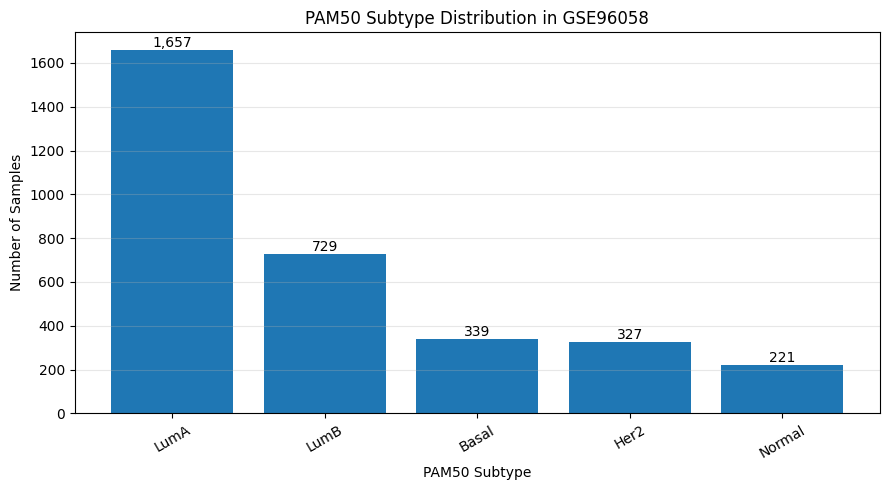

In [ ]:
class_counts = subtype_labels.value_counts().sort_values(ascending=False)
class_percentages = subtype_labels.value_counts(normalize=True) * 100

summary = pd.DataFrame({
    "Sample Count": class_counts,
    "Percentage (%)": class_percentages
})

print(summary.round(2))

plt.figure(figsize=(9, 5))
bars = plt.bar(class_counts.index, class_counts.values)

plt.title("PAM50 Subtype Distribution in GSE96058")
plt.xlabel("PAM50 Subtype")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

for bar, count in zip(bars, class_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

**Interpretation — subtype distribution.** This chart shows the number of samples in each recorded PAM50 class and makes class imbalance visible before modeling. Because LumA is the largest class, later evaluation should include per-class recall and macro-F1 rather than relying on accuracy alone.

### Gene-Expression Value Distribution

This analysis examines the distribution of expression values in the processed
matrix. The dataset contains transformed expression values, so negative values
are not automatically errors.

A subset of genes is sampled for visualization to avoid plotting all features
at once. The full dataset is still used for the quality checks above.

EXPRESSION VALUE SUMMARY
----------------------------------------
count    1.010211e+08
mean    -1.600000e-02
std      3.330000e+00
min     -3.322000e+00
25%     -3.322000e+00
50%     -9.060000e-01
75%      2.865000e+00
max      2.500000e+01
dtype: float64


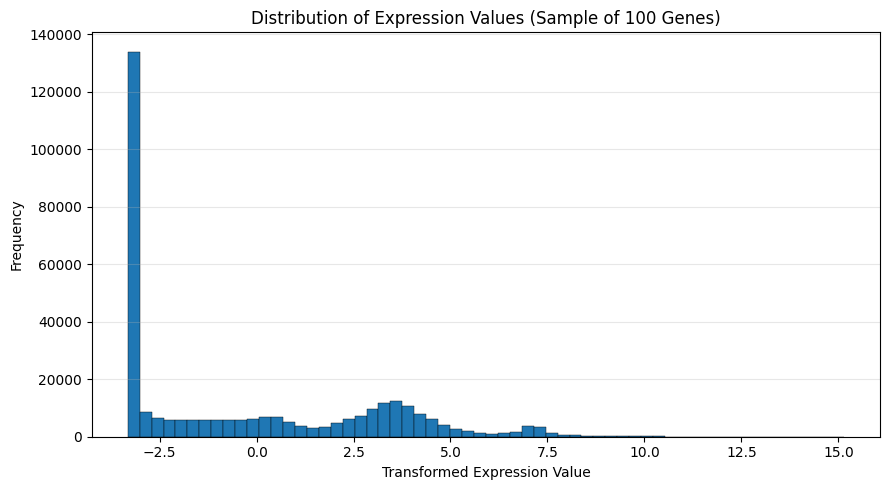

In [ ]:
# Use numeric expression columns only
numeric_data = gene_data.select_dtypes(include=np.number)

print("EXPRESSION VALUE SUMMARY")
print("-" * 40)
print(numeric_data.stack().describe().round(3))

# Select up to 100 genes reproducibly
sampled_genes = numeric_data.sample(
    n=min(100, numeric_data.shape[1]),
    axis=1,
    random_state=42
)

sampled_values = sampled_genes.to_numpy().ravel()
sampled_values = sampled_values[np.isfinite(sampled_values)]

plt.figure(figsize=(9, 5))
plt.hist(sampled_values, bins=60, edgecolor="black", linewidth=0.3)

plt.title("Distribution of Expression Values (Sample of 100 Genes)")
plt.xlabel("Transformed Expression Value")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

**Interpretation — expression-value distribution.** The histogram summarizes the scale and spread of the supplied log2-transformed expression values across a reproducible sample of genes. This helps detect implausible ranges or unusual tails; it does not replace per-sample normalization checks or justify applying another log transform.

Gene variance summary:
count    30865.0000
mean         0.8463
std          2.5352
min          0.0000
25%          0.1250
50%          0.2952
75%          0.7420
max        121.6681
dtype: float64

Top 10 most variable genes:
gene
JC037706    121.668082
DQ597485     94.022674
DQ584545     92.028183
DQ572382     79.037604
DQ590013     67.391444
DQ584699     62.083964
KF274566     57.336245
Histone3     52.573895
SNORD81      51.776320
DQ580854     51.048109
dtype: float64

Genes with zero variance: 0


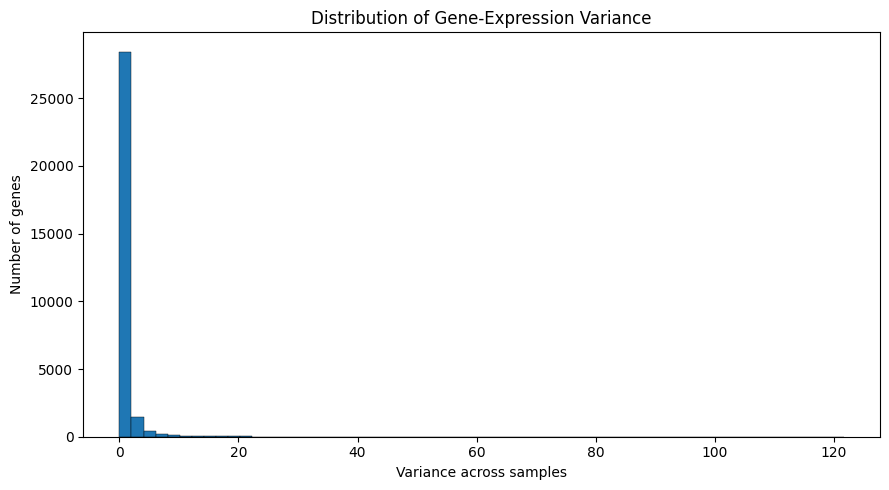

In [ ]:
# Calculate variance for each gene across samples
gene_variance = gene_data.var(axis=0).sort_values(ascending=False)

print("Gene variance summary:")
print(gene_variance.describe().round(4))

print("\nTop 10 most variable genes:")
print(gene_variance.head(10))

print("\nGenes with zero variance:", (gene_variance == 0).sum())

plt.figure(figsize=(9, 5))
plt.hist(gene_variance, bins=60, edgecolor="black", linewidth=0.3)
plt.title("Distribution of Gene-Expression Variance")
plt.xlabel("Variance across samples")
plt.ylabel("Number of genes")
plt.tight_layout()
plt.show()

**Interpretation — gene variance.** The variance distribution shows how much expression variability differs across genes across the cohort. High variance can help identify informative features, but variance alone does not establish subtype specificity or biological importance.

Genes selected for visualization: ['JC037706', 'DQ597485', 'DQ584545']


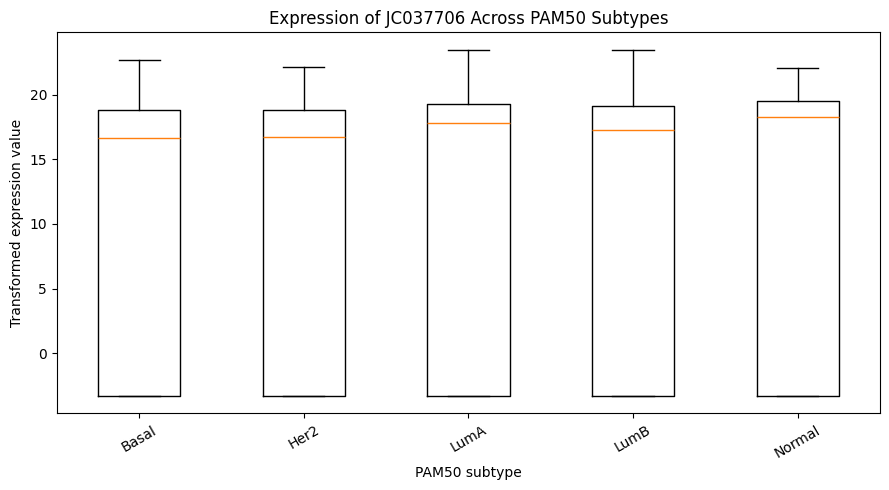

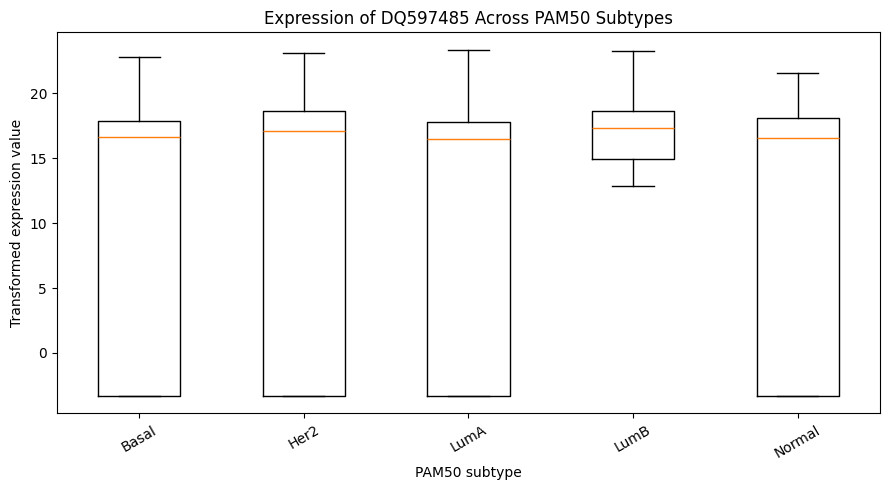

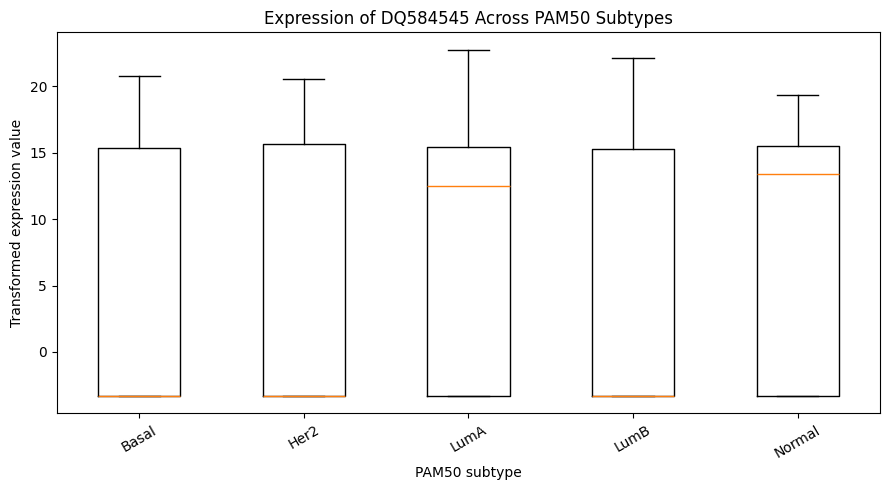

In [ ]:
top_genes = gene_variance.head(3).index.tolist()

print("Genes selected for visualization:", top_genes)

for gene in top_genes:
    plt.figure(figsize=(9, 5))

    groups = [
        gene_data.loc[subtype_labels == subtype, gene].dropna().values
        for subtype in sorted(subtype_labels.dropna().unique())
    ]

    plt.boxplot(
        groups,
        tick_labels=sorted(subtype_labels.dropna().unique()),
        showfliers=False
    )

    plt.title(f"Expression of {gene} Across PAM50 Subtypes")
    plt.xlabel("PAM50 subtype")
    plt.ylabel("Transformed expression value")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

**Interpretation — most variable genes by subtype.** These boxplots compare the expression distributions of the three highest-variance genes across the five recorded PAM50 groups. Differences may motivate further investigation, but selecting genes based on the full dataset before evaluation can leak information; feature selection for predictive evaluation should be fitted inside each training fold.

## PAM50 signature coverage and biologically relevant genes

The PAM50 reference list contains 50 historical gene symbols. In the executed expression matrix, **49/50 symbols match exactly**; `ORC6L` does not occur under that name, but `ORC6` is present. **NCBI Gene (human Gene ID 23594) explicitly lists `ORC6L` as another name for `ORC6`**, so all 50 reference genes are represented **after this documented one-to-one symbol mapping**. This is a symbol-identity check, not a reproduction of the original PAM50 centroid classifier. The expression matrix is retained unchanged; any future PAM50-panel model must apply the mapping explicitly and record its feature names.

- PAM50 gene list: [UCSC Xena tutorial](https://ucsc-xena.gitbook.io/project/tutorials/advanced-tutorial-section-2).
- Alias verification: [NCBI Gene — ORC6 (Gene ID 23594)](https://www.ncbi.nlm.nih.gov/gene/23594).

**Execution evidence:** The outputs below were produced after the duplicate-gene and ORC6 alias-check cells were added. The code reports the exact-symbol match count separately from the alias-resolved count.

In [ ]:
PAM50_GENES = [
    "UBE2T", "BIRC5", "NUF2", "CDC6", "CCNB1", "TYMS", "MYBL2", "CEP55",
    "MELK", "NDC80", "RRM2", "UBE2C", "CENPF", "PTTG1", "EXO1", "ORC6L",
    "ANLN", "CCNE1", "CDC20", "MKI67", "KIF2C", "ACTR3B", "MYC", "EGFR",
    "KRT5", "PHGDH", "CDH3", "MIA", "KRT17", "FOXC1", "SFRP1", "KRT14",
    "ESR1", "SLC39A6", "BAG1", "MAPT", "PGR", "CXXC5", "MLPH", "BCL2",
    "MDM2", "NAT1", "FOXA1", "BLVRA", "MMP11", "GPR160", "FGFR4", "GRB7",
    "TMEM45B", "ERBB2"
]

# Normalize only for comparison; retain original gene-symbol columns in X.
normalized_gene_lookup = {str(g).strip().upper(): g for g in gene_data.columns}
pam50_present = [g for g in PAM50_GENES if g in normalized_gene_lookup]
pam50_missing = [g for g in PAM50_GENES if g not in normalized_gene_lookup]

print(f"PAM50 genes in reference list: {len(PAM50_GENES)}")
print(f"PAM50 genes found in expression matrix: {len(pam50_present)} / {len(PAM50_GENES)}")
print("Present:", pam50_present)
print("Missing:", pam50_missing)

assert len(PAM50_GENES) == 50, "Reference PAM50 panel should contain 50 symbols."
# ORC6L is a historical symbol for ORC6. Check alias explicitly without
# silently changing the gene identifiers or the already-recorded 49/50 result.
orc6_alias_candidates = [g for g in ("ORC6L", "ORC6") if g in normalized_gene_lookup]
print("ORC6L / ORC6 gene-symbol check:", orc6_alias_candidates or "Neither exact symbol found")
if "ORC6L" not in normalized_gene_lookup and "ORC6" in normalized_gene_lookup:
    print("Potential alias match: ORC6 exists. Validate official gene identity before treating PAM50 coverage as 50/50.")
elif "ORC6L" not in normalized_gene_lookup:
    print("Neither ORC6L nor ORC6 is present under these exact symbols; inspect gene annotation before concluding it is absent.")

# NCBI Gene ID 23594 documents ORC6L as a historical name of ORC6.
# For reporting only: preserve all original matrix column names.
resolved_pam50 = {g: ("ORC6" if g == "ORC6L" and "ORC6" in normalized_gene_lookup else g) for g in PAM50_GENES}
resolved_present = [g for g, actual in resolved_pam50.items() if actual in normalized_gene_lookup]
print(f"PAM50 coverage after documented ORC6L -> ORC6 mapping: {len(resolved_present)}/50")
print("Gene-symbol mapping reference: NCBI Gene 23594 (ORC6; also known as ORC6L)")


PAM50 genes in reference list: 50
PAM50 genes found in expression matrix: 49 / 50
Present: ['UBE2T', 'BIRC5', 'NUF2', 'CDC6', 'CCNB1', 'TYMS', 'MYBL2', 'CEP55', 'MELK', 'NDC80', 'RRM2', 'UBE2C', 'CENPF', 'PTTG1', 'EXO1', 'ANLN', 'CCNE1', 'CDC20', 'MKI67', 'KIF2C', 'ACTR3B', 'MYC', 'EGFR', 'KRT5', 'PHGDH', 'CDH3', 'MIA', 'KRT17', 'FOXC1', 'SFRP1', 'KRT14', 'ESR1', 'SLC39A6', 'BAG1', 'MAPT', 'PGR', 'CXXC5', 'MLPH', 'BCL2', 'MDM2', 'NAT1', 'FOXA1', 'BLVRA', 'MMP11', 'GPR160', 'FGFR4', 'GRB7', 'TMEM45B', 'ERBB2']
Missing: ['ORC6L']
ORC6L / ORC6 gene-symbol check: ['ORC6']
Potential alias match: ORC6 exists. Validate official gene identity before treating PAM50 coverage as 50/50.
PAM50 coverage after documented ORC6L -> ORC6 mapping: 50/50
Gene-symbol mapping reference: NCBI Gene 23594 (ORC6; also known as ORC6L)


### ESR1, ERBB2, and MKI67 expression by PAM50 subtype

These genes are included because they are biologically interpretable breast-cancer markers: ESR1 is associated with estrogen-receptor biology, ERBB2 with HER2 biology, and MKI67 with proliferation. The cell plots whichever of these exact gene symbols are available in the expression matrix and clearly reports unavailable symbols rather than silently substituting another feature.

Marker genes available: ['ESR1', 'ERBB2', 'MKI67']
Marker genes missing: []


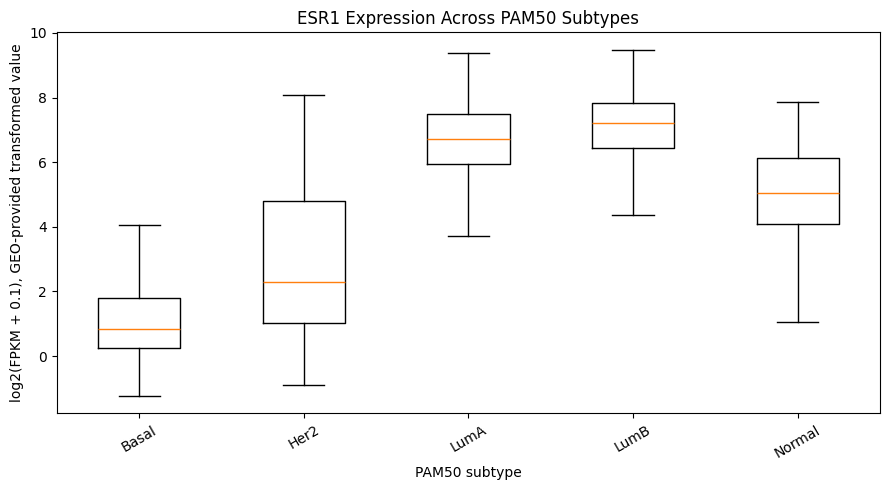

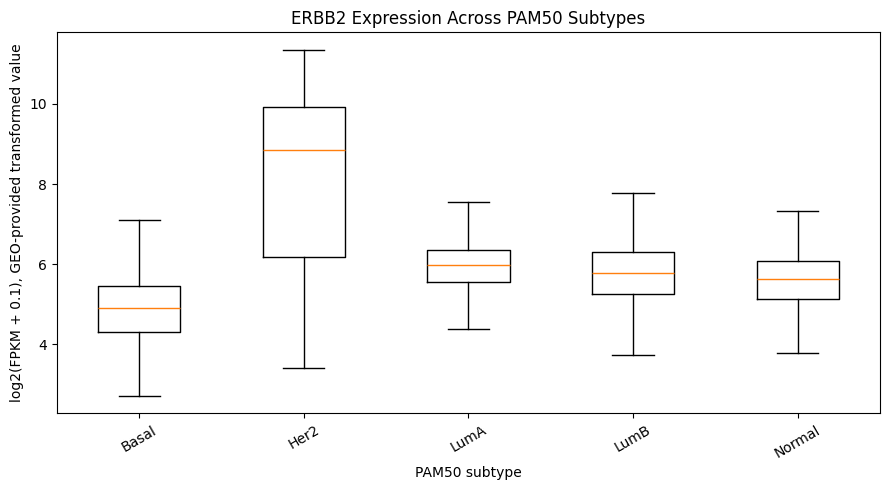

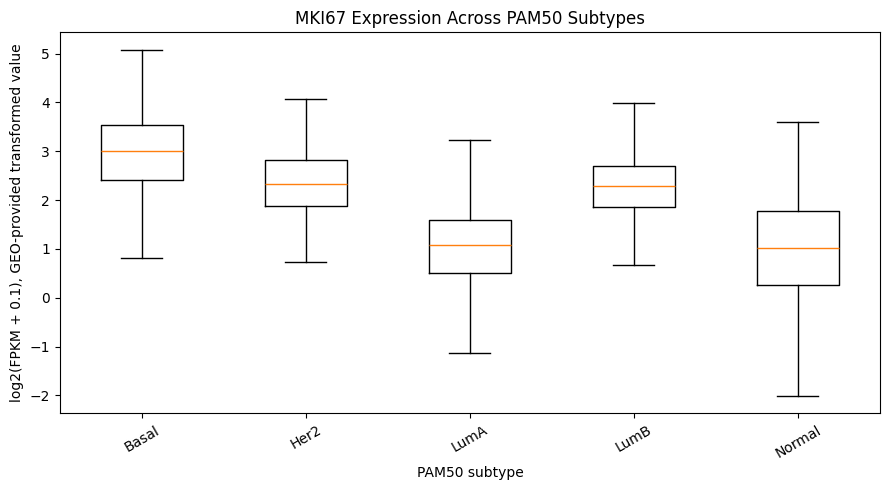

Interpretation: These plots compare marker-expression distributions across the metadata-provided PAM50 groups. They are descriptive and may help contextualize model features, but they do not establish causality or independently validate the subtype labels.


In [ ]:
MARKER_GENES = ["ESR1", "ERBB2", "MKI67"]
marker_lookup = {str(g).strip().upper(): g for g in gene_data.columns}
markers_found = [g for g in MARKER_GENES if g in marker_lookup]
markers_missing = [g for g in MARKER_GENES if g not in marker_lookup]

print("Marker genes available:", markers_found)
print("Marker genes missing:", markers_missing)

subtype_order = sorted(subtype_labels.dropna().unique())
for requested_gene in markers_found:
    gene = marker_lookup[requested_gene]
    groups = [
        gene_data.loc[subtype_labels == subtype, gene].dropna().values
        for subtype in subtype_order
    ]
    plt.figure(figsize=(9, 5))
    plt.boxplot(groups, tick_labels=subtype_order, showfliers=False)
    plt.title(f"{requested_gene} Expression Across PAM50 Subtypes")
    plt.xlabel("PAM50 subtype")
    plt.ylabel("log2(FPKM + 0.1), GEO-provided transformed value")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

print("Interpretation: These plots compare marker-expression distributions across the metadata-provided PAM50 groups. They are descriptive and may help contextualize model features, but they do not establish causality or independently validate the subtype labels.")

### Initial EDA conclusions

- The recorded executed run prepared **3,273 primary breast tumor samples** with **30,865 expression features** and PAM50 subtype labels; **136 replicate-suffixed measurements** were excluded.
- The five PAM50 categories are imbalanced; Luminal A is the largest category (**1,657 samples**). This motivates macro-F1 and subtype-wise metrics in later modeling.
- Saved quality-check outputs report no missing or infinite expression values, duplicate gene/sample identifiers, or missing primary-sample PAM50 labels.
- The source matrix contains processed, log-transformed expression values, which this notebook does **not** transform again.
- The executed PAM50 lookup confirmed 49/50 exact gene-symbol matches and 50/50 matches after alias resolution. The expression matrix contains ORC6, which corresponds to the historical PAM50 gene symbol ORC6L, as verified through NCBI Gene (Gene ID 23594).

**Interpretation limits:** These findings document initial dataset inspection and exploratory analysis, not model accuracy, clinical suitability, or cross-cohort generalization. Feature selection and model evaluation remain future steps.

## Reproducibility and submission checklist

**Verified from saved outputs in this notebook**
- [x] Source expression file and GEO SOFT metadata were downloaded in the recorded run.
- [x] The matrix was inspected and retained in its provided processed expression scale (`log2(FPKM + 0.1)`); no second log transform was applied.
- [x] Primary sample IDs were matched to GEO PAM50 annotations, with no missing labels reported.
- [x] The 136 replicate-suffixed columns were excluded from the primary-sample table.
- [x] Full-data and chunked gene-identifier checks recorded no duplicate gene symbols.
- [x] PAM50 and marker-gene checks were executed; `ORC6` was present and `ORC6L` absent as an exact symbol.
- [x] Output messages show that both cleaned CSV export commands completed.
- [x] PAM50 coverage was confirmed as 49/50 exact-symbol matches and 50/50 after resolving ORC6L to ORC6.


**Still to verify separately**

- [ ] Independently reopen and validate the exported CSV files (the notebook records writes, not an independent post-export readback).
- [ ] Ensure downloaded source data and large generated CSVs are excluded from the GitHub repository.

**Scope:** Data preparation and exploratory analysis only. PAM50 labels are provided by GEO metadata, and later predictive models will be evaluated for agreement with those labels. Gene-attribution outputs are not causal biological evidence.